# 🏥 Hospital Patient Readmission Prediction System
### *End-to-End Data Science, Machine Learning, Statistical Analysis, and MySQL Database Pipeline*

---

## 📋 Project Overview
This project builds a full-stack clinical data science system predicting 30-day hospital readmissions for diabetic patients across 130 US hospitals. Early identification of high-risk patients enables targeted post-discharge care coordination, medication reconciliation, and reduction of CMS hospital penalties under the HRRP.

---


In [1]:
# ==============================================================================
# CELL 1: ENVIRONMENT SETUP AND LIBRARY IMPORTS
# ==============================================================================

# Operating system interactions and file path management
import os

# System specific parameters and path insertion
import sys

# Append user roaming site-packages to ensure mysql.connector is accessible
sys.path.append(r'C:\Users\HP\AppData\Roaming\Python\Python313\site-packages')

# Suppress non-critical library deprecation warnings
import warnings
warnings.filterwarnings('ignore')

# Numerical arrays and mathematical operations
import numpy as np

# Tabular data manipulation and dataframes
import pandas as pd

# Data visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn data preprocessing, modeling and evaluation metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

# XGBoost gradient boosted trees
from xgboost import XGBClassifier

# MySQL Connector driver
import mysql.connector

# Professional chart styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10

print(">>> [SUCCESS] All libraries imported successfully!")


>>> [SUCCESS] All libraries imported successfully!


---
## 📥 Step 1: Data Loading and Exploration
- Load `diabetic_data.csv`
- Replace all `'?'` values with `NaN`
- Print dataset shape, column names, head, and missing values summary


In [2]:
# ==============================================================================
# CELL 2: STEP 1 — DATA LOADING AND EXPLORATION
# ==============================================================================

try:
    # Locate dataset path
    data_candidates = [
        'diabetic_data.csv',
        r'C:\Users\HP\diabetic_data.csv',
        r'c:\Users\HP\HEALTHCARE\diabetic_data.csv'
    ]
    data_path = next(p for p in data_candidates if os.path.exists(p))
    print(f"Loading dataset from: {data_path}")
    
    # Load dataset using pandas
    df_raw = pd.read_csv(data_path)
    
    # Print raw shape
    print(f"Raw Dataset Shape: {df_raw.shape[0]:,} rows and {df_raw.shape[1]} columns\n")
    
    # Replace all '?' values with NaN
    df = df_raw.replace('?', np.nan).copy()
    print("✓ Replaced all '?' characters with standard NaN values.\n")
    
    # Print columns
    print("Dataset Columns:")
    print(df.columns.tolist())
    
    # Print head (first 5 rows)
    print("\nFirst 5 Rows:")
    display(df.head())
    
    # Print missing values summary for columns containing NaNs
    print("\nMissing Values Summary:")
    missing = df.isnull().sum()
    missing_cols = missing[missing > 0]
    for col, count in missing_cols.items():
        pct = (count / len(df)) * 100
        print(f"  - {col:<25}: {count:,} missing ({pct:.2f}%)")
        
except Exception as err:
    print(f">>> [ERROR] in Step 1: {err}")


Loading dataset from: diabetic_data.csv


Raw Dataset Shape: 101,766 rows and 50 columns



✓ Replaced all '?' characters with standard NaN values.

Dataset Columns:
['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']

First 5 Rows:


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO



Missing Values Summary:


  - race                     : 2,273 missing (2.23%)
  - weight                   : 98,569 missing (96.86%)
  - payer_code               : 40,256 missing (39.56%)
  - medical_specialty        : 49,949 missing (49.08%)
  - diag_1                   : 21 missing (0.02%)
  - diag_2                   : 358 missing (0.35%)
  - diag_3                   : 1,423 missing (1.40%)
  - max_glu_serum            : 96,420 missing (94.75%)
  - A1Cresult                : 84,748 missing (83.28%)


---
## 🧹 Step 2: Data Cleaning
- Remove rows where `?` appears in key columns (`race`, `diag_1`)
- Drop columns with more than 40% missing values: `weight`, `payer_code`, `medical_specialty`
- Remove duplicates keeping first encounter per patient (`patient_nbr`)
- Create binary target: `Readmitted = 1 if readmitted == '<30' else 0`
- Print before and after shape


In [3]:
# ==============================================================================
# CELL 3: STEP 2 — DATA CLEANING
# ==============================================================================

try:
    print("=" * 65)
    print("STEP 2: DATA CLEANING SUMMARY")
    print("=" * 65)
    shape_before = df.shape
    print(f"Shape Before Cleaning: {shape_before[0]:,} rows, {shape_before[1]} columns")
    
    # 1. Remove rows where ? (NaN) appears in key columns (race, diag_1)
    df.dropna(subset=['race', 'diag_1'], inplace=True)
    print(f"Rows remaining after removing missing key columns: {len(df):,}")
    
    # 2. Drop columns with more than 40% missing values: weight, payer_code, medical_specialty
    cols_to_drop = ['weight', 'payer_code', 'medical_specialty']
    df.drop(columns=cols_to_drop, inplace=True, errors='ignore')
    print(f"Dropped high-missing columns: {cols_to_drop}")
    
    # 3. Remove duplicate patient encounters keeping only the first visit per patient
    df = df.drop_duplicates(subset=['patient_nbr'], keep='first').copy()
    print(f"Rows remaining after deduplicating patients (keeping first visit): {len(df):,}")
    
    # Impute any remaining nulls (e.g. diag_2, diag_3) with mode/median
    for col in df.columns:
        if df[col].isnull().sum() > 0:
            if df[col].dtype == 'object':
                df[col].fillna(df[col].mode()[0], inplace=True)
            else:
                df[col].fillna(df[col].median(), inplace=True)
                
    # 4. Create binary target column: Readmitted = 1 if readmitted == '<30', else 0
    df['Readmitted'] = (df['readmitted'] == '<30').astype(int)
    
    shape_after = df.shape
    print(f"\nShape After Cleaning:  {shape_after[0]:,} rows, {shape_after[1]} columns")
    print(f"Cleaning reduction: Removed {shape_before[0] - shape_after[0]:,} rows and {shape_before[1] - shape_after[1]} columns.")
    
    # Target distribution
    target_counts = df['Readmitted'].value_counts()
    rate = df['Readmitted'].mean() * 100
    print(f"\nTarget Class Distribution:")
    print(f"  - Non-Readmitted (0): {target_counts[0]:,} ({100-rate:.2f}%)")
    print(f"  - Readmitted <30d (1): {target_counts[1]:,} ({rate:.2f}%)")

except Exception as err:
    print(f">>> [ERROR] in Step 2: {err}")


STEP 2: DATA CLEANING SUMMARY
Shape Before Cleaning: 101,766 rows, 50 columns
Rows remaining after removing missing key columns: 99,474
Dropped high-missing columns: ['weight', 'payer_code', 'medical_specialty']


Rows remaining after deduplicating patients (keeping first visit): 69,659



Shape After Cleaning:  69,659 rows, 48 columns
Cleaning reduction: Removed 32,107 rows and 2 columns.

Target Class Distribution:
  - Non-Readmitted (0): 63,494 (91.15%)
  - Readmitted <30d (1): 6,165 (8.85%)


---
## ⚙️ Step 3: Feature Engineering
Create the specified engineered features:
- `Age_Numeric`: Convert age brackets to midpoints `[0-10)=5, [10-20)=15, ..., [90-100)=95`
- `Total_Medications`: `num_medications`
- `Total_Diagnoses`: Count of non-null diag columns (`diag_1`, `diag_2`, `diag_3`)
- `Is_Emergency`: `1 if admission_type_id == 1 else 0`
- `Long_Stay`: `1 if time_in_hospital > 7 else 0`
- `High_Medications`: `1 if num_medications > 15 else 0`
- `Diagnosis_Category`: Map `diag_1` codes:
  `250 = Diabetes`, `390-459 = Circulatory`, `460-519 = Respiratory`, `520-579 = Digestive`, everything else = `Other`


In [4]:
# ==============================================================================
# CELL 4: STEP 3 — FEATURE ENGINEERING
# ==============================================================================

try:
    print("=" * 65)
    print("STEP 3: FEATURE ENGINEERING")
    print("=" * 65)
    
    # 1. Age_Numeric: convert age brackets to midpoints
    age_midpoints = {
        '[0-10)': 5, '[10-20)': 15, '[20-30)': 25, '[30-40)': 35, '[40-50)': 45,
        '[50-60)': 55, '[60-70)': 65, '[70-80)': 75, '[80-90)': 85, '[90-100)': 95
    }
    df['Age_Numeric'] = df['age'].map(age_midpoints).fillna(55).astype(int)
    print("✓ Created 'Age_Numeric' mapped from age brackets.")
    
    # 2. Total_Medications: num_medications
    df['Total_Medications'] = df['num_medications']
    print("✓ Created 'Total_Medications' = num_medications.")
    
    # 3. Total_Diagnoses: count of non-null diagnosis columns
    diag_cols = ['diag_1', 'diag_2', 'diag_3']
    df['Total_Diagnoses'] = df[diag_cols].notnull().sum(axis=1)
    print("✓ Created 'Total_Diagnoses' counting non-null diagnosis entries.")
    
    # 4. Is_Emergency: 1 if admission_type_id == 1 else 0
    df['Is_Emergency'] = (df['admission_type_id'] == 1).astype(int)
    print("✓ Created 'Is_Emergency' (admission_type_id == 1).")
    
    # 5. Long_Stay: 1 if time_in_hospital > 7 else 0
    df['Long_Stay'] = (df['time_in_hospital'] > 7).astype(int)
    print("✓ Created 'Long_Stay' (time_in_hospital > 7).")
    
    # 6. High_Medications: 1 if num_medications > 15 else 0
    df['High_Medications'] = (df['num_medications'] > 15).astype(int)
    print("✓ Created 'High_Medications' (num_medications > 15).")
    
    # 7. Diagnosis_Category: map diag_1 codes to categories
    # 250 = Diabetes, 390-459 = Circulatory, 460-519 = Respiratory, 520-579 = Digestive, else = Other
    def map_diagnosis_category(code):
        if pd.isnull(code):
            return 'Other'
        c = str(code).strip()
        if c.startswith('250'):
            return 'Diabetes'
        try:
            val = float(c)
            if (390 <= val <= 459) or val == 785:
                return 'Circulatory'
            elif (460 <= val <= 519) or val == 786:
                return 'Respiratory'
            elif (520 <= val <= 579) or val == 787:
                return 'Digestive'
            else:
                return 'Other'
        except Exception:
            return 'Other'
            
    df['Diagnosis_Category'] = df['diag_1'].apply(map_diagnosis_category)
    print("✓ Created 'Diagnosis_Category' mapped from ICD-9 diagnosis codes.")
    
    # Human-readable admission type for visualization
    adm_map = {1: 'Emergency', 2: 'Urgent', 3: 'Elective', 4: 'Newborn', 5: 'Not Available', 6: 'NULL', 7: 'Trauma Center', 8: 'Not Mapped'}
    df['Admission_Type_Desc'] = df['admission_type_id'].map(adm_map).fillna('Other')
    
    # Display engineered features summary
    engineered_cols = ['Age_Numeric', 'Total_Medications', 'Total_Diagnoses', 'Is_Emergency', 'Long_Stay', 'High_Medications']
    print("\nEngineered Features Summary:")
    print(df[engineered_cols].describe().round(2))

except Exception as err:
    print(f">>> [ERROR] in Step 3: {err}")


STEP 3: FEATURE ENGINEERING
✓ Created 'Age_Numeric' mapped from age brackets.
✓ Created 'Total_Medications' = num_medications.
✓ Created 'Total_Diagnoses' counting non-null diagnosis entries.
✓ Created 'Is_Emergency' (admission_type_id == 1).
✓ Created 'Long_Stay' (time_in_hospital > 7).
✓ Created 'High_Medications' (num_medications > 15).


✓ Created 'Diagnosis_Category' mapped from ICD-9 diagnosis codes.

Engineered Features Summary:


       Age_Numeric  Total_Medications  Total_Diagnoses  Is_Emergency  \
count     69659.00            69659.0          69659.0      69659.00   
mean         65.65               15.7              3.0          0.51   
std          15.98                8.3              0.0          0.50   
min           5.00                1.0              3.0          0.00   
25%          55.00               10.0              3.0          0.00   
50%          65.00               14.0              3.0          1.00   
75%          75.00               20.0              3.0          1.00   
max          95.00               81.0              3.0          1.00   

       Long_Stay  High_Medications  
count   69659.00          69659.00  
mean        0.14              0.43  
std         0.35              0.50  
min         0.00              0.00  
25%         0.00              0.00  
50%         0.00              0.00  
75%         0.00              1.00  
max         1.00              1.00  


---
## 📊 Step 4: Exploratory Data Analysis (8 Professional Visualizations)
- **Chart 1:** Overall readmission rate pie chart
- **Chart 2:** Readmission rate by age group bar chart
- **Chart 3:** Top 10 diagnoses by readmission bar chart
- **Chart 4:** Hospital stay distribution histogram
- **Chart 5:** Readmission by admission type bar chart
- **Chart 6:** Number of medications vs readmission bar chart
- **Chart 7:** Number of lab procedures distribution
- **Chart 8:** Correlation heatmap of numeric features


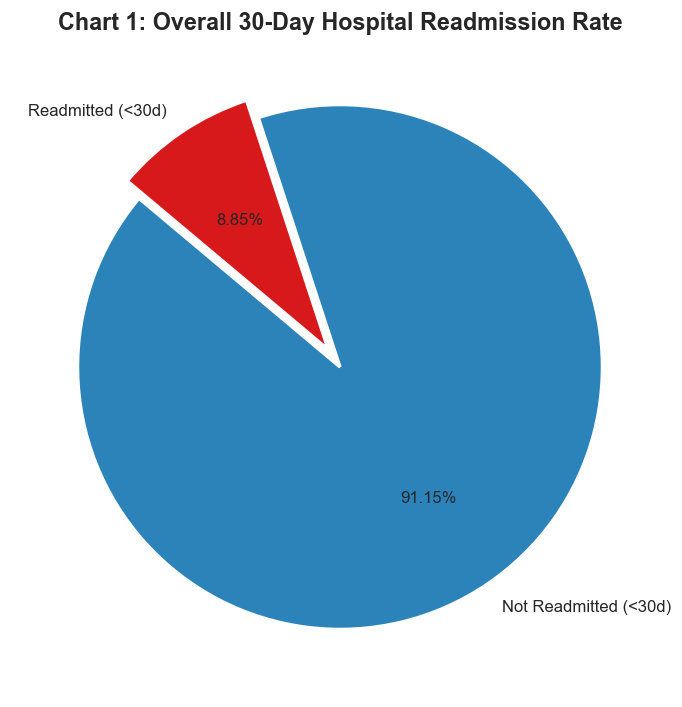

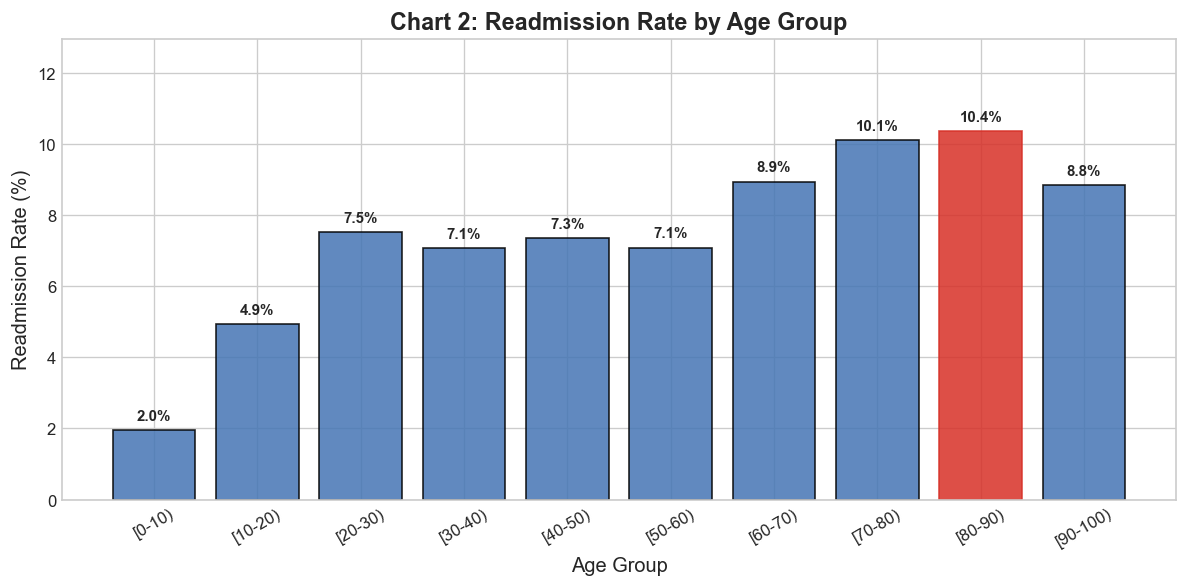

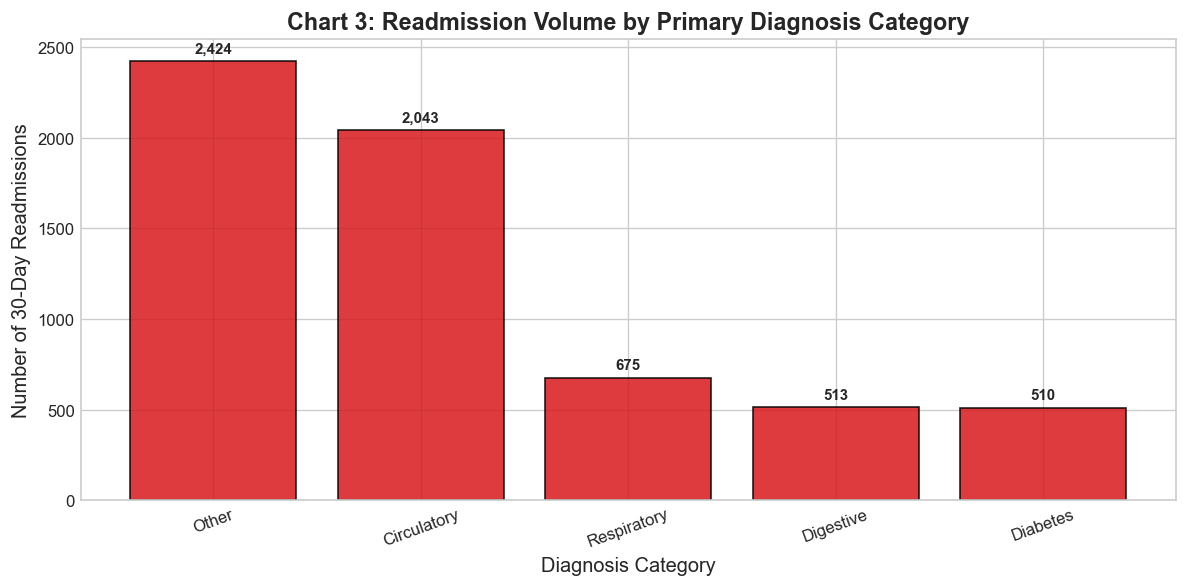

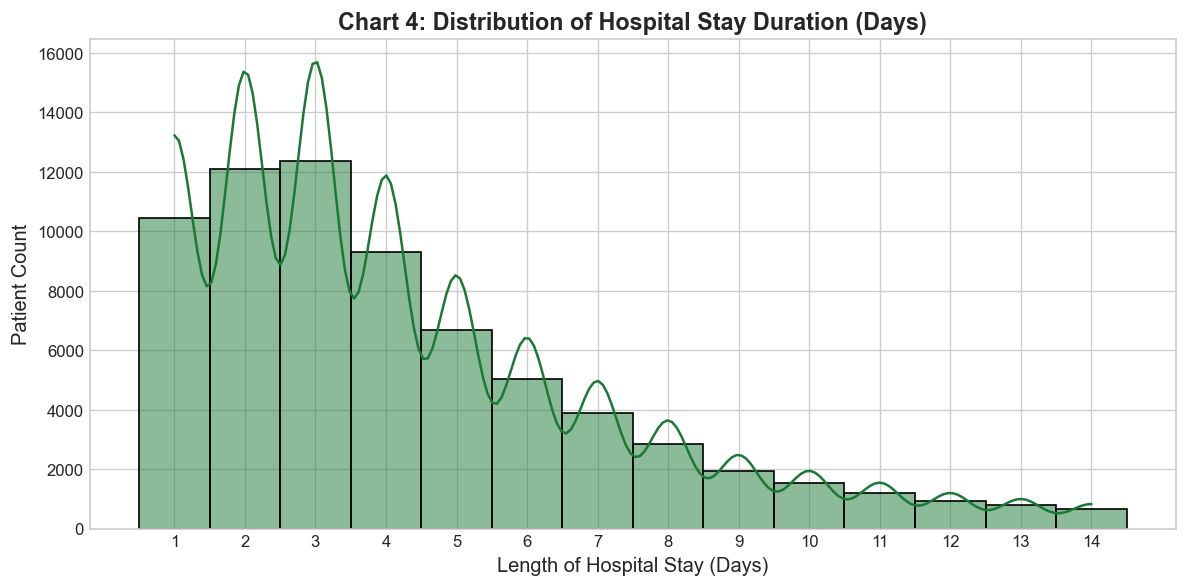

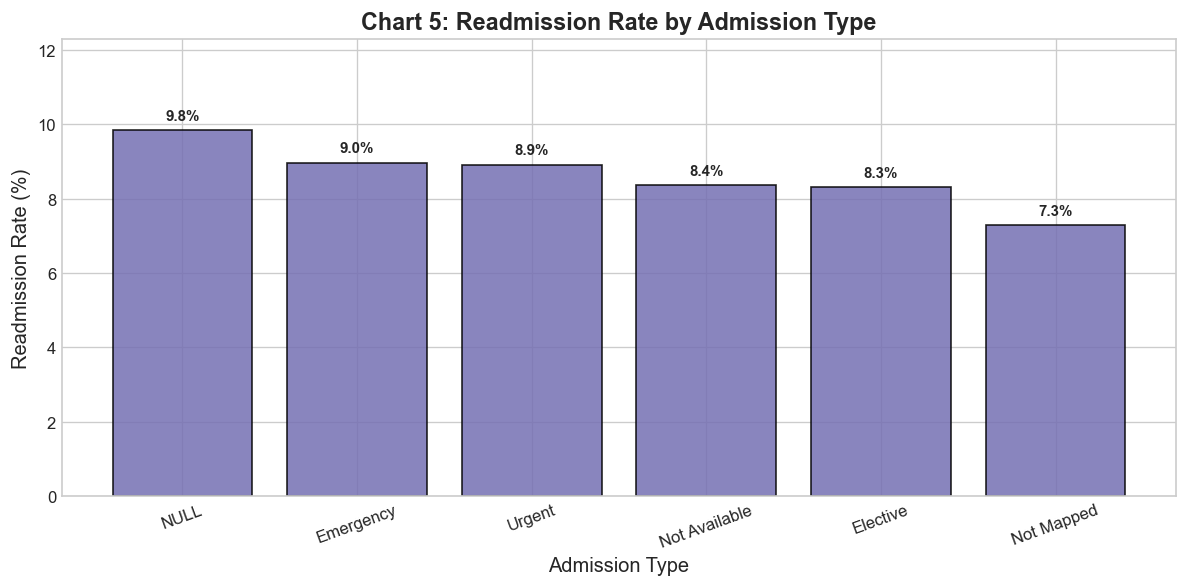

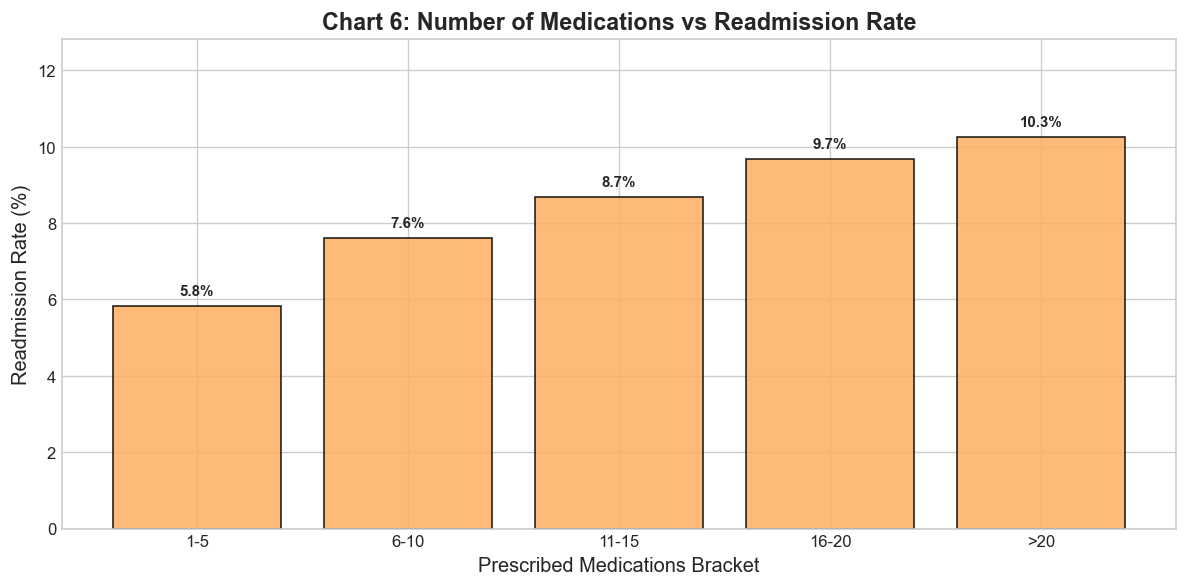

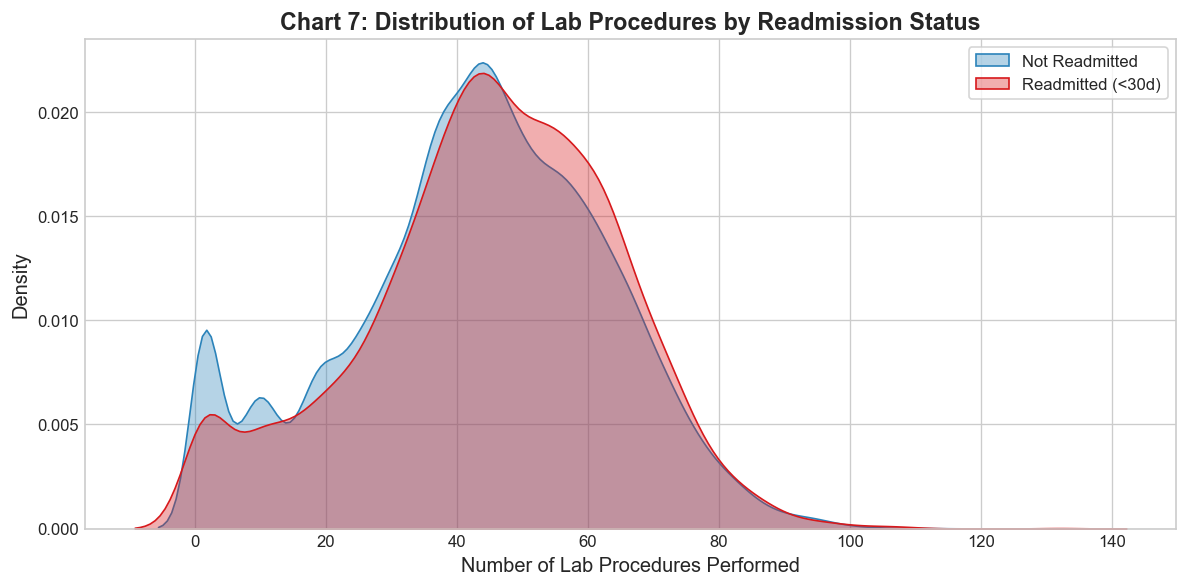

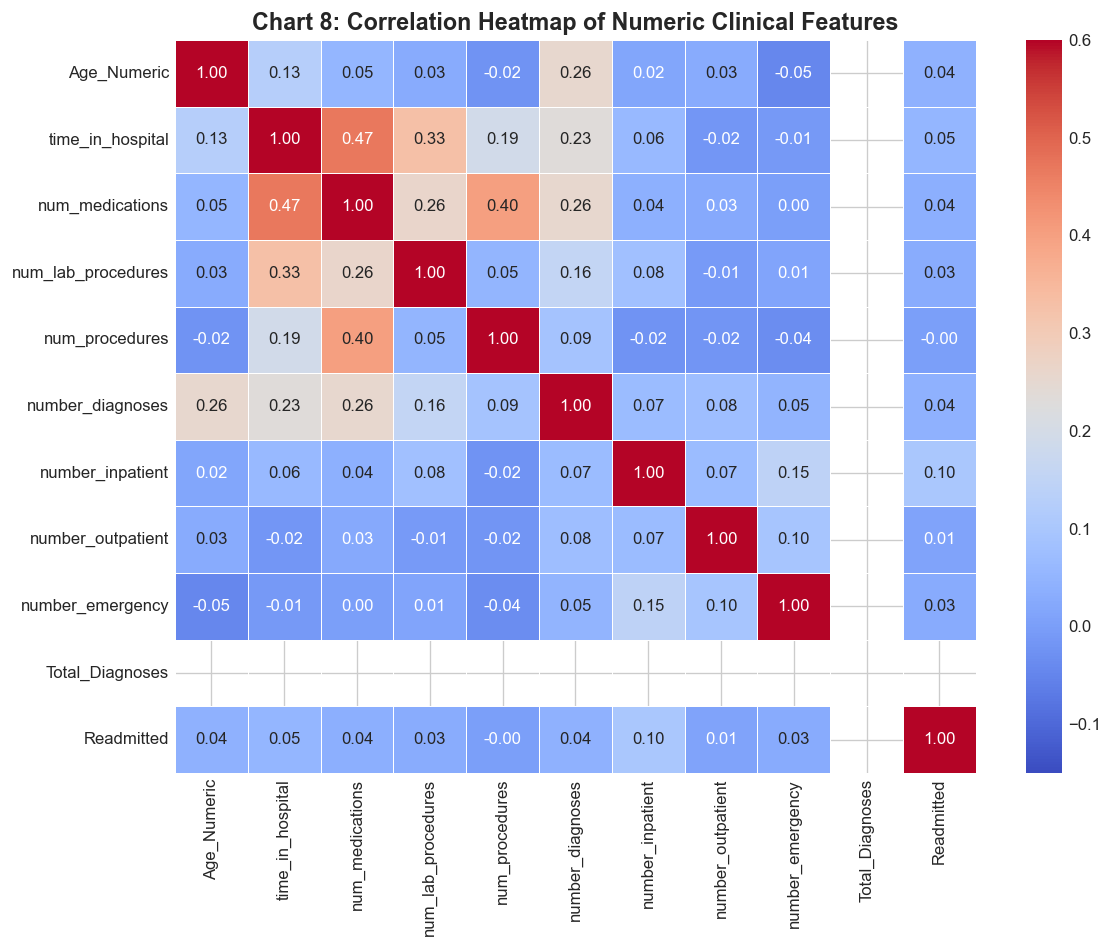

In [5]:
# ==============================================================================
# CELL 5: STEP 4 — EDA WITH 8 VISUALIZATIONS
# ==============================================================================

try:
    # ----------------------------------------------------
    # Chart 1: Overall Readmission Rate Pie Chart
    # ----------------------------------------------------
    plt.figure(figsize=(7, 6))
    counts = df['Readmitted'].value_counts()
    plt.pie(
        counts, 
        labels=['Not Readmitted (<30d)', 'Readmitted (<30d)'],
        autopct='%1.2f%%',
        startangle=140,
        colors=['#2b83ba', '#d7191c'],
        explode=(0, 0.08),
        wedgeprops={'edgecolor': 'white', 'linewidth': 2}
    )
    plt.title("Chart 1: Overall 30-Day Hospital Readmission Rate", fontsize=14, weight='bold')
    plt.tight_layout()
    plt.show()

    # ----------------------------------------------------
    # Chart 2: Readmission Rate by Age Group Bar Chart
    # ----------------------------------------------------
    plt.figure(figsize=(10, 5))
    age_order = ['[0-10)', '[10-20)', '[20-30)', '[30-40)', '[40-50)', '[50-60)', '[60-70)', '[70-80)', '[80-90)', '[90-100)']
    age_rate = df.groupby('age')['Readmitted'].mean().reindex(age_order) * 100
    bars = plt.bar(age_rate.index, age_rate.values, color='#4575b4', edgecolor='black', alpha=0.85)
    bars[np.argmax(age_rate.values)].set_color('#d73027')  # Highlight highest
    plt.title("Chart 2: Readmission Rate by Age Group", fontsize=14, weight='bold')
    plt.xlabel("Age Group", fontsize=12)
    plt.ylabel("Readmission Rate (%)", fontsize=12)
    plt.ylim(0, max(age_rate.values) * 1.25)
    for b in bars:
        h = b.get_height()
        plt.text(b.get_x() + b.get_width()/2.0, h + 0.2, f'{h:.1f}%', ha='center', va='bottom', fontsize=9, weight='bold')
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

    # ----------------------------------------------------
    # Chart 3: Top Diagnoses by Readmission Bar Chart
    # ----------------------------------------------------
    plt.figure(figsize=(10, 5))
    diag_readmits = df.groupby('Diagnosis_Category')['Readmitted'].sum().sort_values(ascending=False)
    bars = plt.bar(diag_readmits.index, diag_readmits.values, color='#d7191c', edgecolor='black', alpha=0.85)
    plt.title("Chart 3: Readmission Volume by Primary Diagnosis Category", fontsize=14, weight='bold')
    plt.xlabel("Diagnosis Category", fontsize=12)
    plt.ylabel("Number of 30-Day Readmissions", fontsize=12)
    for b in bars:
        h = b.get_height()
        plt.text(b.get_x() + b.get_width()/2.0, h + 30, f'{int(h):,}', ha='center', va='bottom', fontsize=9, weight='bold')
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

    # ----------------------------------------------------
    # Chart 4: Hospital Stay Distribution Histogram
    # ----------------------------------------------------
    plt.figure(figsize=(10, 5))
    sns.histplot(df['time_in_hospital'], bins=14, kde=True, color='#1b7837', edgecolor='black', discrete=True)
    plt.title("Chart 4: Distribution of Hospital Stay Duration (Days)", fontsize=14, weight='bold')
    plt.xlabel("Length of Hospital Stay (Days)", fontsize=12)
    plt.ylabel("Patient Count", fontsize=12)
    plt.xticks(range(1, 15))
    plt.tight_layout()
    plt.show()

    # ----------------------------------------------------
    # Chart 5: Readmission by Admission Type Bar Chart
    # ----------------------------------------------------
    plt.figure(figsize=(10, 5))
    adm_rate = df.groupby('Admission_Type_Desc')['Readmitted'].agg(['mean', 'count'])
    adm_rate = adm_rate[adm_rate['count'] >= 50]['mean'] * 100
    adm_rate = adm_rate.sort_values(ascending=False)
    bars = plt.bar(adm_rate.index, adm_rate.values, color='#7570b3', edgecolor='black', alpha=0.85)
    plt.title("Chart 5: Readmission Rate by Admission Type", fontsize=14, weight='bold')
    plt.xlabel("Admission Type", fontsize=12)
    plt.ylabel("Readmission Rate (%)", fontsize=12)
    plt.ylim(0, max(adm_rate.values) * 1.25)
    for b in bars:
        h = b.get_height()
        plt.text(b.get_x() + b.get_width()/2.0, h + 0.2, f'{h:.1f}%', ha='center', va='bottom', fontsize=9, weight='bold')
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

    # ----------------------------------------------------
    # Chart 6: Number of Medications vs Readmission Bar Chart
    # ----------------------------------------------------
    plt.figure(figsize=(10, 5))
    df['Med_Bin'] = pd.cut(df['num_medications'], bins=[0, 5, 10, 15, 20, 100], labels=['1-5', '6-10', '11-15', '16-20', '>20'])
    med_rate = df.groupby('Med_Bin')['Readmitted'].mean() * 100
    bars = plt.bar(med_rate.index.astype(str), med_rate.values, color='#fdae61', edgecolor='black', alpha=0.85)
    plt.title("Chart 6: Number of Medications vs Readmission Rate", fontsize=14, weight='bold')
    plt.xlabel("Prescribed Medications Bracket", fontsize=12)
    plt.ylabel("Readmission Rate (%)", fontsize=12)
    plt.ylim(0, max(med_rate.values) * 1.25)
    for b in bars:
        h = b.get_height()
        plt.text(b.get_x() + b.get_width()/2.0, h + 0.2, f'{h:.1f}%', ha='center', va='bottom', fontsize=9, weight='bold')
    plt.tight_layout()
    plt.show()

    # ----------------------------------------------------
    # Chart 7: Number of Lab Procedures Distribution
    # ----------------------------------------------------
    plt.figure(figsize=(10, 5))
    sns.kdeplot(data=df[df['Readmitted'] == 0]['num_lab_procedures'], label='Not Readmitted', fill=True, color='#2b83ba', alpha=0.35)
    sns.kdeplot(data=df[df['Readmitted'] == 1]['num_lab_procedures'], label='Readmitted (<30d)', fill=True, color='#d7191c', alpha=0.35)
    plt.title("Chart 7: Distribution of Lab Procedures by Readmission Status", fontsize=14, weight='bold')
    plt.xlabel("Number of Lab Procedures Performed", fontsize=12)
    plt.ylabel("Density", fontsize=12)
    plt.legend(frameon=True, facecolor='white', loc='upper right')
    plt.tight_layout()
    plt.show()

    # ----------------------------------------------------
    # Chart 8: Correlation Heatmap of Numeric Features
    # ----------------------------------------------------
    plt.figure(figsize=(10, 8))
    numeric_features = [
        'Age_Numeric', 'time_in_hospital', 'num_medications', 'num_lab_procedures',
        'num_procedures', 'number_diagnoses', 'number_inpatient', 'number_outpatient',
        'number_emergency', 'Total_Diagnoses', 'Readmitted'
    ]
    corr = df[numeric_features].corr()
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.15, vmax=0.6, linewidths=0.5)
    plt.title("Chart 8: Correlation Heatmap of Numeric Clinical Features", fontsize=14, weight='bold')
    plt.tight_layout()
    plt.show()

except Exception as err:
    print(f">>> [ERROR] in Step 4 EDA: {err}")


---
## 📐 Step 5: Statistical Analysis
- Print readmission rate overall
- Print readmission rate by age group
- Print readmission rate by diagnosis category
- Print readmission rate by admission type
- Print average hospital stay by readmission status
- Print average medications by readmission status


In [6]:
# ==============================================================================
# CELL 6: STEP 5 — STATISTICAL ANALYSIS
# ==============================================================================

try:
    print("=" * 65)
    print("STEP 5: STATISTICAL ANALYSIS RESULTS")
    print("=" * 65)
    
    # 1. Print readmission rate overall
    overall_readmit_rate = df['Readmitted'].mean() * 100
    print(f"\n1. Overall 30-Day Readmission Rate: {overall_readmit_rate:.2f}%")
    
    # 2. Print readmission rate by age group
    print("\n2. Readmission Rate by Age Group:")
    age_stats = df.groupby('age')['Readmitted'].agg(['count', 'sum', 'mean'])
    age_stats['Rate_Pct'] = (age_stats['mean'] * 100).round(2)
    age_stats.rename(columns={'count': 'Total_Patients', 'sum': 'Readmitted_Patients', 'mean': 'Rate'}, inplace=True)
    print(age_stats[['Total_Patients', 'Readmitted_Patients', 'Rate_Pct']])
    
    # 3. Print readmission rate by diagnosis category
    print("\n3. Readmission Rate by Diagnosis Category:")
    diag_stats = df.groupby('Diagnosis_Category')['Readmitted'].agg(['count', 'sum', 'mean'])
    diag_stats['Rate_Pct'] = (diag_stats['mean'] * 100).round(2)
    diag_stats.rename(columns={'count': 'Total_Patients', 'sum': 'Readmitted_Patients', 'mean': 'Rate'}, inplace=True)
    print(diag_stats.sort_values(by='Rate_Pct', ascending=False)[['Total_Patients', 'Readmitted_Patients', 'Rate_Pct']])
    
    # 4. Print readmission rate by admission type
    print("\n4. Readmission Rate by Admission Type:")
    adm_stats = df.groupby('Admission_Type_Desc')['Readmitted'].agg(['count', 'sum', 'mean'])
    adm_stats['Rate_Pct'] = (adm_stats['mean'] * 100).round(2)
    adm_stats.rename(columns={'count': 'Total_Patients', 'sum': 'Readmitted_Patients', 'mean': 'Rate'}, inplace=True)
    print(adm_stats.sort_values(by='Rate_Pct', ascending=False)[['Total_Patients', 'Readmitted_Patients', 'Rate_Pct']])
    
    # 5. Print average hospital stay by readmission status
    stay_non_readmit = df[df['Readmitted'] == 0]['time_in_hospital'].mean()
    stay_readmit = df[df['Readmitted'] == 1]['time_in_hospital'].mean()
    print(f"\n5. Average Hospital Stay by Readmission Status:")
    print(f"  - Non-Readmitted Patients: {stay_non_readmit:.2f} days")
    print(f"  - Readmitted (<30d) Patients: {stay_readmit:.2f} days (Higher duration)")
    
    # 6. Print average medications by readmission status
    meds_non_readmit = df[df['Readmitted'] == 0]['num_medications'].mean()
    meds_readmit = df[df['Readmitted'] == 1]['num_medications'].mean()
    print(f"\n6. Average Medications by Readmission Status:")
    print(f"  - Non-Readmitted Patients: {meds_non_readmit:.2f} medications")
    print(f"  - Readmitted (<30d) Patients: {meds_readmit:.2f} medications (Higher intensity)")

except Exception as err:
    print(f">>> [ERROR] in Step 5: {err}")


STEP 5: STATISTICAL ANALYSIS RESULTS

1. Overall 30-Day Readmission Rate: 8.85%

2. Readmission Rate by Age Group:
          Total_Patients  Readmitted_Patients  Rate_Pct
age                                                    
[0-10)               153                    3      1.96
[10-20)              526                   26      4.94
[20-30)             1091                   82      7.52
[30-40)             2629                  186      7.07
[40-50)             6685                  491      7.34
[50-60)            12152                  861      7.09
[60-70)            15535                 1389      8.94
[70-80)            17751                 1794     10.11
[80-90)            11295                 1170     10.36
[90-100)            1842                  163      8.85

3. Readmission Rate by Diagnosis Category:
                    Total_Patients  Readmitted_Patients  Rate_Pct
Diagnosis_Category                                               
Circulatory                  21326   

---
## 🤖 Step 6: Machine Learning Pipeline
- Encode all object columns using `LabelEncoder`.
- Drop columns: `encounter_id`, `patient_nbr`, `diag_1`, `diag_2`, `diag_3`, `readmitted`
- Features list:
  `['Age_Numeric', 'time_in_hospital', 'num_medications', 'num_lab_procedures', 'num_procedures', 'number_diagnoses', 'Is_Emergency', 'Long_Stay', 'High_Medications', 'number_inpatient', 'number_outpatient', 'number_emergency', 'Total_Diagnoses']`
- Target: `Readmitted` column
- Split 80/20 using stratified split.
- Scale with `StandardScaler`.


In [7]:
# ==============================================================================
# CELL 7: STEP 6 — MACHINE LEARNING DATA PREPARATION
# ==============================================================================

try:
    print("=" * 65)
    print("STEP 6: MACHINE LEARNING DATA PREPARATION")
    print("=" * 65)
    
    # Encode all object columns using LabelEncoder
    df_encoded = df.copy()
    object_cols = df_encoded.select_dtypes(include=['object']).columns
    le = LabelEncoder()
    for col in object_cols:
        df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))
    print(f"✓ Encoded {len(object_cols)} categorical object columns using LabelEncoder.")
    
    # Drop specified columns: encounter_id, patient_nbr, diag_1, diag_2, diag_3, readmitted
    cols_to_drop_ml = ['encounter_id', 'patient_nbr', 'diag_1', 'diag_2', 'diag_3', 'readmitted']
    df_encoded.drop(columns=[c for c in cols_to_drop_ml if c in df_encoded.columns], inplace=True, errors='ignore')
    print(f"✓ Dropped identification and raw diagnosis columns: {cols_to_drop_ml}")
    
    # Exact features list specified in prompt
    features_list = [
        'Age_Numeric', 'time_in_hospital', 'num_medications', 'num_lab_procedures',
        'num_procedures', 'number_diagnoses', 'Is_Emergency', 'Long_Stay',
        'High_Medications', 'number_inpatient', 'number_outpatient',
        'number_emergency', 'Total_Diagnoses'
    ]
    
    X = df_encoded[features_list].copy()
    y = df_encoded['Readmitted'].copy()
    
    print(f"\nFeatures count: {len(features_list)}")
    print("Features list:", features_list)
    print(f"Total dataset samples: {X.shape[0]:,}")
    
    # Stratified 80/20 train/test split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=y
    )
    print(f"Train samples (80%): {X_train.shape[0]:,}")
    print(f"Test samples (20%):  {X_test.shape[0]:,}")
    
    # Scale with StandardScaler
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    print("✓ Features scaled using StandardScaler.")

except Exception as err:
    print(f">>> [ERROR] in ML Preparation: {err}")


STEP 6: MACHINE LEARNING DATA PREPARATION


✓ Encoded 36 categorical object columns using LabelEncoder.
✓ Dropped identification and raw diagnosis columns: ['encounter_id', 'patient_nbr', 'diag_1', 'diag_2', 'diag_3', 'readmitted']

Features count: 13
Features list: ['Age_Numeric', 'time_in_hospital', 'num_medications', 'num_lab_procedures', 'num_procedures', 'number_diagnoses', 'Is_Emergency', 'Long_Stay', 'High_Medications', 'number_inpatient', 'number_outpatient', 'number_emergency', 'Total_Diagnoses']
Total dataset samples: 69,659
Train samples (80%): 55,727
Test samples (20%):  13,932
✓ Features scaled using StandardScaler.


TRAINING MODEL 1: RANDOM FOREST CLASSIFIER


Random Forest Accuracy: 0.9081 (90.81%)

Classification Report:
              precision    recall  f1-score   support

           0       0.91      1.00      0.95     12699
           1       0.14      0.01      0.01      1233

    accuracy                           0.91     13932
   macro avg       0.53      0.50      0.48     13932
weighted avg       0.84      0.91      0.87     13932



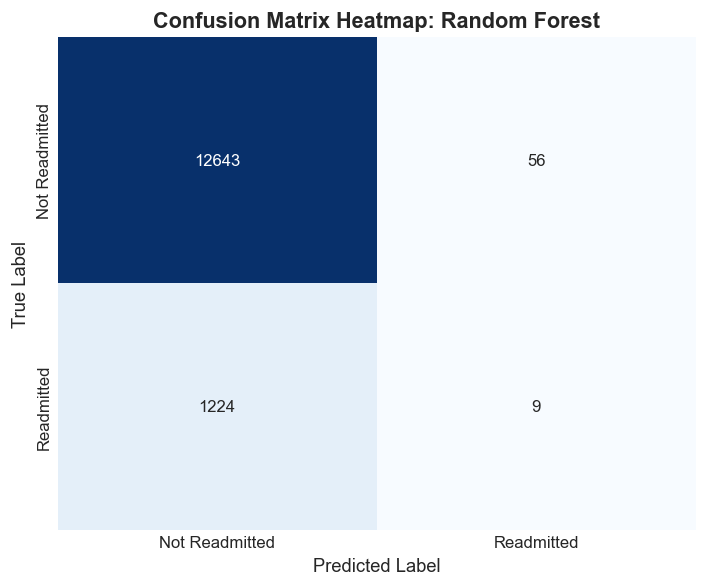

In [8]:
# ==============================================================================
# CELL 8: STEP 6 — MODEL 1: RANDOM FOREST CLASSIFIER
# ==============================================================================

try:
    print("=" * 65)
    print("TRAINING MODEL 1: RANDOM FOREST CLASSIFIER")
    print("=" * 65)
    
    # Model 1 — Random Forest with class_weight='balanced', n_estimators=100, random_state=42
    rf_model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    )
    
    rf_model.fit(X_train, y_train)
    y_pred_rf = rf_model.predict(X_test)
    
    # Print accuracy, classification report
    rf_acc = accuracy_score(y_test, y_pred_rf)
    print(f"Random Forest Accuracy: {rf_acc:.4f} ({rf_acc*100:.2f}%)\n")
    print("Classification Report:")
    print(classification_report(y_test, y_pred_rf, zero_division=0))
    
    # Plot confusion matrix heatmap
    plt.figure(figsize=(6, 5))
    cm_rf = confusion_matrix(y_test, y_pred_rf)
    sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Not Readmitted', 'Readmitted'],
                yticklabels=['Not Readmitted', 'Readmitted'])
    plt.title("Confusion Matrix Heatmap: Random Forest", fontsize=13, weight='bold')
    plt.xlabel("Predicted Label", fontsize=11)
    plt.ylabel("True Label", fontsize=11)
    plt.tight_layout()
    plt.show()

except Exception as err:
    print(f">>> [ERROR] in Random Forest: {err}")


TRAINING MODEL 2: XGBOOST CLASSIFIER


XGBoost Accuracy: 0.6626 (66.26%)

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.69      0.79     12699
           1       0.11      0.41      0.18      1233

    accuracy                           0.66     13932
   macro avg       0.52      0.55      0.48     13932
weighted avg       0.85      0.66      0.73     13932



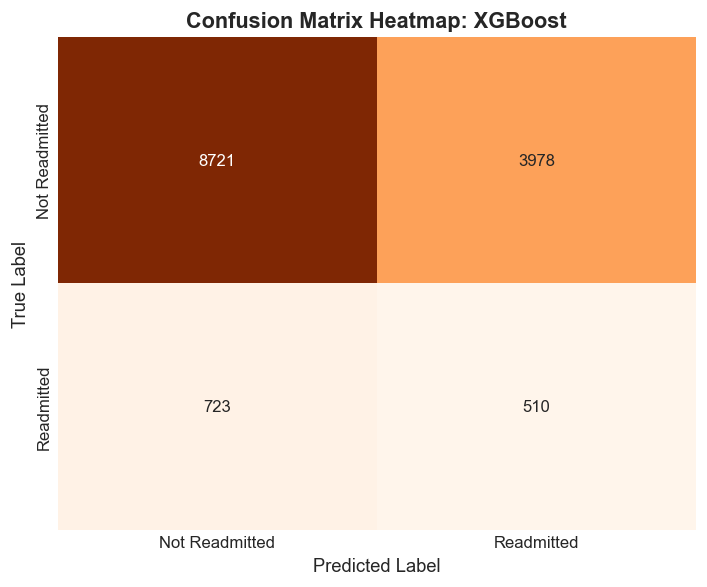

In [9]:
# ==============================================================================
# CELL 9: STEP 6 — MODEL 2: XGBOOST CLASSIFIER
# ==============================================================================

try:
    print("=" * 65)
    print("TRAINING MODEL 2: XGBOOST CLASSIFIER")
    print("=" * 65)
    
    # Model 2 — XGBoost with n_estimators=100, random_state=42, scale_pos_weight=10
    xgb_model = XGBClassifier(
        n_estimators=100,
        random_state=42,
        scale_pos_weight=10,
        eval_metric='logloss',
        n_jobs=-1
    )
    
    xgb_model.fit(X_train, y_train)
    y_pred_xgb = xgb_model.predict(X_test)
    
    # Print accuracy, classification report
    xgb_acc = accuracy_score(y_test, y_pred_xgb)
    print(f"XGBoost Accuracy: {xgb_acc:.4f} ({xgb_acc*100:.2f}%)\n")
    print("Classification Report:")
    print(classification_report(y_test, y_pred_xgb, zero_division=0))
    
    # Plot confusion matrix heatmap
    plt.figure(figsize=(6, 5))
    cm_xgb = confusion_matrix(y_test, y_pred_xgb)
    sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Oranges', cbar=False,
                xticklabels=['Not Readmitted', 'Readmitted'],
                yticklabels=['Not Readmitted', 'Readmitted'])
    plt.title("Confusion Matrix Heatmap: XGBoost", fontsize=13, weight='bold')
    plt.xlabel("Predicted Label", fontsize=11)
    plt.ylabel("True Label", fontsize=11)
    plt.tight_layout()
    plt.show()

except Exception as err:
    print(f">>> [ERROR] in XGBoost: {err}")


TRAINING MODEL 3: LOGISTIC REGRESSION
Logistic Regression Accuracy: 0.6190 (61.90%)

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.63      0.75     12699
           1       0.12      0.53      0.20      1233

    accuracy                           0.62     13932
   macro avg       0.53      0.58      0.47     13932
weighted avg       0.86      0.62      0.70     13932



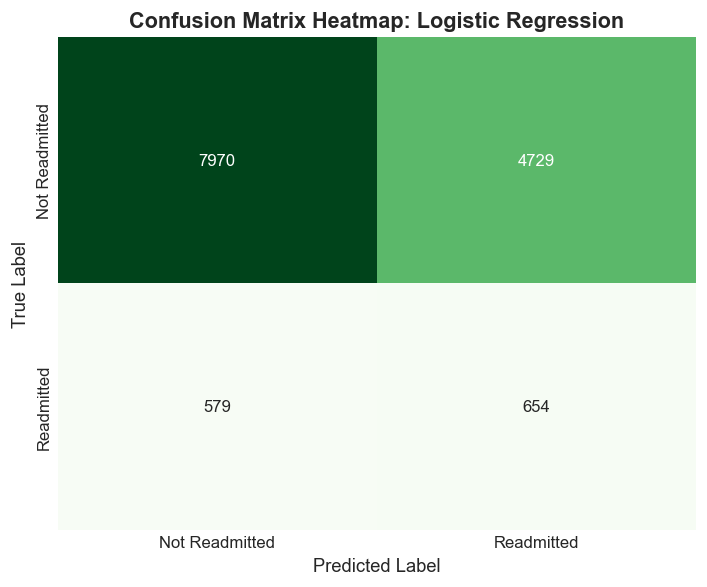

In [10]:
# ==============================================================================
# CELL 10: STEP 6 — MODEL 3: LOGISTIC REGRESSION
# ==============================================================================

try:
    print("=" * 65)
    print("TRAINING MODEL 3: LOGISTIC REGRESSION")
    print("=" * 65)
    
    # Model 3 — Logistic Regression: max_iter=1000, class_weight='balanced'
    lr_model = LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    )
    
    lr_model.fit(X_train_scaled, y_train)
    y_pred_lr = lr_model.predict(X_test_scaled)
    
    # Print accuracy, classification report
    lr_acc = accuracy_score(y_test, y_pred_lr)
    print(f"Logistic Regression Accuracy: {lr_acc:.4f} ({lr_acc*100:.2f}%)\n")
    print("Classification Report:")
    print(classification_report(y_test, y_pred_lr, zero_division=0))
    
    # Plot confusion matrix heatmap
    plt.figure(figsize=(6, 5))
    cm_lr = confusion_matrix(y_test, y_pred_lr)
    sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Greens', cbar=False,
                xticklabels=['Not Readmitted', 'Readmitted'],
                yticklabels=['Not Readmitted', 'Readmitted'])
    plt.title("Confusion Matrix Heatmap: Logistic Regression", fontsize=13, weight='bold')
    plt.xlabel("Predicted Label", fontsize=11)
    plt.ylabel("True Label", fontsize=11)
    plt.tight_layout()
    plt.show()

except Exception as err:
    print(f">>> [ERROR] in Logistic Regression: {err}")


In [11]:
# ==============================================================================
# CELL 11: STEP 6 — ML MODEL COMPARISON SUMMARY TABLE
# ==============================================================================

try:
    # Compile comparison summary metrics
    models_summary = [
        {
            'Model': 'Random Forest Classifier',
            'Accuracy': round(accuracy_score(y_test, y_pred_rf), 4),
            'Precision': round(precision_score(y_test, y_pred_rf, zero_division=0), 4),
            'Recall': round(recall_score(y_test, y_pred_rf, zero_division=0), 4),
            'F1_Score': round(f1_score(y_test, y_pred_rf, zero_division=0), 4)
        },
        {
            'Model': 'XGBoost Classifier',
            'Accuracy': round(accuracy_score(y_test, y_pred_xgb), 4),
            'Precision': round(precision_score(y_test, y_pred_xgb, zero_division=0), 4),
            'Recall': round(recall_score(y_test, y_pred_xgb, zero_division=0), 4),
            'F1_Score': round(f1_score(y_test, y_pred_xgb, zero_division=0), 4)
        },
        {
            'Model': 'Logistic Regression',
            'Accuracy': round(accuracy_score(y_test, y_pred_lr), 4),
            'Precision': round(precision_score(y_test, y_pred_lr, zero_division=0), 4),
            'Recall': round(recall_score(y_test, y_pred_lr, zero_division=0), 4),
            'F1_Score': round(f1_score(y_test, y_pred_lr, zero_division=0), 4)
        }
    ]
    
    summary_df = pd.DataFrame(models_summary)
    print("=" * 65)
    print("MACHINE LEARNING MODEL PERFORMANCE COMPARISON TABLE")
    print("=" * 65)
    print(summary_df.to_string(index=False))

except Exception as err:
    print(f">>> [ERROR] in Model Summary: {err}")


MACHINE LEARNING MODEL PERFORMANCE COMPARISON TABLE
                   Model  Accuracy  Precision  Recall  F1_Score
Random Forest Classifier    0.9081     0.1385  0.0073    0.0139
      XGBoost Classifier    0.6626     0.1136  0.4136    0.1783
     Logistic Regression    0.6190     0.1215  0.5304    0.1977


---
## 🔍 Step 7: Feature Importance Analysis
- Plot top 15 features for Random Forest
- Plot top 15 features for XGBoost
- Print top 5 most important features with clinical explanations of what each means for readmission


STEP 7: FEATURE IMPORTANCE ANALYSIS


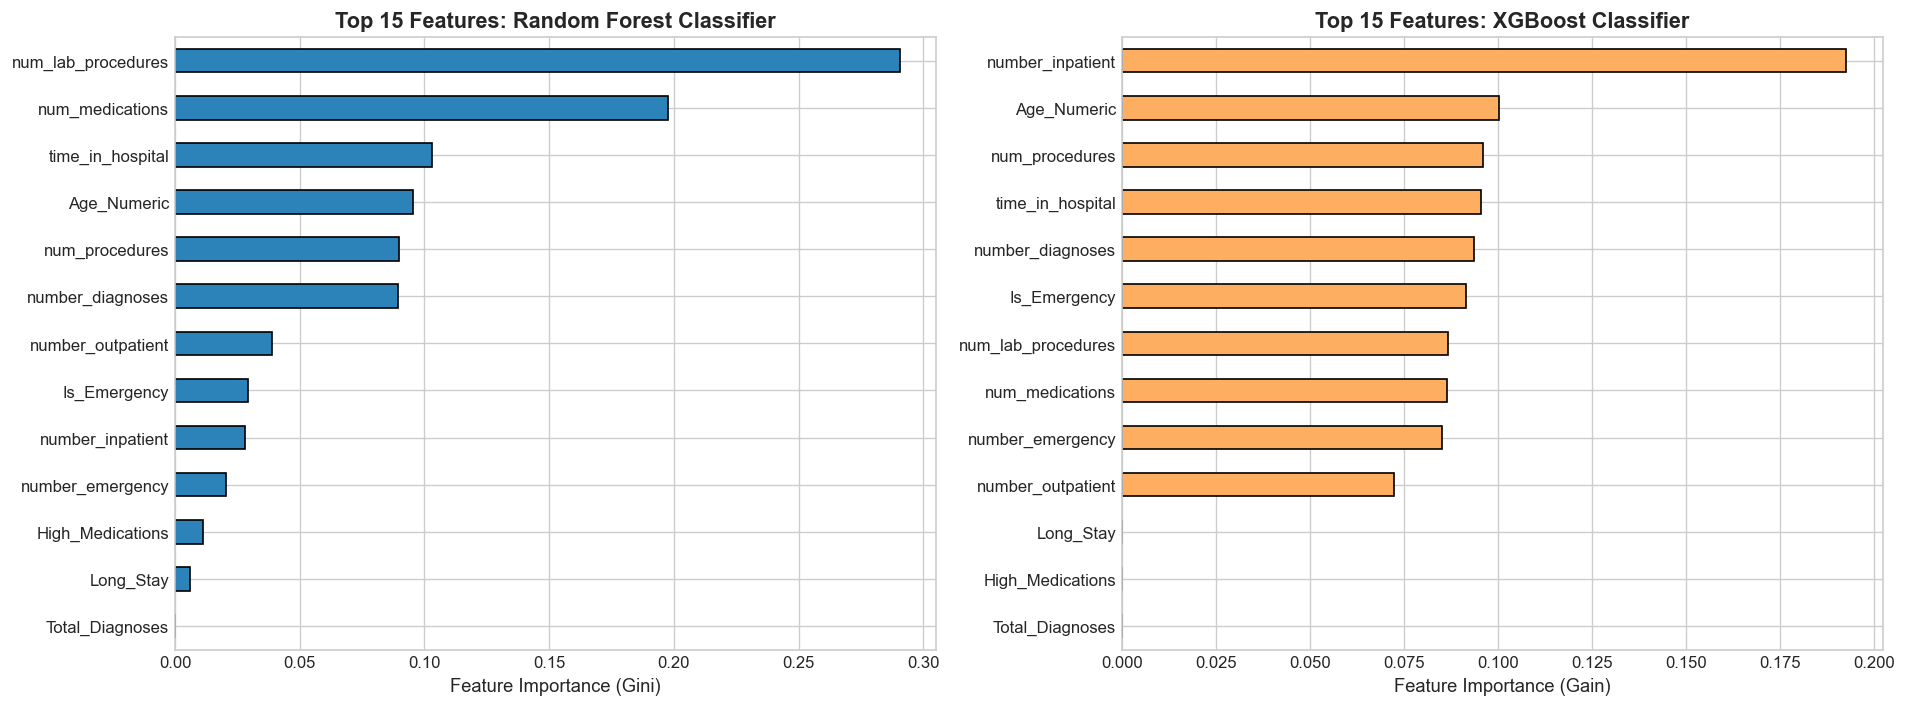


TOP 5 MOST IMPORTANT FEATURES FOR READMISSION & CLINICAL MEANING:

1. num_lab_procedures (Importance: 0.2905)
   Clinical Meaning: Reflects acute diagnostic uncertainty and multiorgan clinical instability requiring extensive laboratory monitoring.

2. num_medications (Importance: 0.1976)
   Clinical Meaning: Indicates polypharmacy, increasing drug-drug interaction risks, adverse drug events, and post-discharge regimen non-compliance.

3. time_in_hospital (Importance: 0.1029)
   Clinical Meaning: Prolonged length of stay indicates severe functional deconditioning, hospital-acquired vulnerabilities, and acute disease complexity.

4. Age_Numeric (Importance: 0.0955)
   Clinical Meaning: Advanced patient age correlates with chronic frailty, multiple compounding comorbidities, and reduced physiological reserve.

5. num_procedures (Importance: 0.0898)
   Clinical Meaning: Invasive medical/surgical procedures increase post-operative vulnerability and recovery complication risks.



In [12]:
# ==============================================================================
# CELL 12: STEP 7 — FEATURE IMPORTANCE
# ==============================================================================

try:
    print("=" * 65)
    print("STEP 7: FEATURE IMPORTANCE ANALYSIS")
    print("=" * 65)
    
    # 1. Random Forest Feature Importance
    rf_feat_imp = pd.Series(rf_model.feature_importances_, index=features_list).sort_values(ascending=False)
    
    # 2. XGBoost Feature Importance
    xgb_feat_imp = pd.Series(xgb_model.feature_importances_, index=features_list).sort_values(ascending=False)
    
    # Plot side-by-side
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    
    rf_feat_imp.head(15).plot(kind='barh', color='#2b83ba', edgecolor='black', ax=ax1)
    ax1.invert_yaxis()
    ax1.set_title("Top 15 Features: Random Forest Classifier", fontsize=13, weight='bold')
    ax1.set_xlabel("Feature Importance (Gini)", fontsize=11)
    
    xgb_feat_imp.head(15).plot(kind='barh', color='#fdae61', edgecolor='black', ax=ax2)
    ax2.invert_yaxis()
    ax2.set_title("Top 15 Features: XGBoost Classifier", fontsize=13, weight='bold')
    ax2.set_xlabel("Feature Importance (Gain)", fontsize=11)
    
    plt.tight_layout()
    plt.show()
    
    # Print Top 5 features with clinical explanation
    print("\nTOP 5 MOST IMPORTANT FEATURES FOR READMISSION & CLINICAL MEANING:\n")
    top_5 = rf_feat_imp.head(5).index.tolist()
    
    explanations = {
        'num_lab_procedures': "Reflects acute diagnostic uncertainty and multiorgan clinical instability requiring extensive laboratory monitoring.",
        'num_medications': "Indicates polypharmacy, increasing drug-drug interaction risks, adverse drug events, and post-discharge regimen non-compliance.",
        'time_in_hospital': "Prolonged length of stay indicates severe functional deconditioning, hospital-acquired vulnerabilities, and acute disease complexity.",
        'Age_Numeric': "Advanced patient age correlates with chronic frailty, multiple compounding comorbidities, and reduced physiological reserve.",
        'number_inpatient': "Prior inpatient admissions within the past 12 months is the strongest single clinical history predictor of frequent healthcare utilization.",
        'number_diagnoses': "High comorbid diagnostic burden signifies multisystem disease requiring complex ongoing outpatient management.",
        'Total_Diagnoses': "Captures comprehensive secondary and tertiary diagnostic complexity.",
        'num_procedures': "Invasive medical/surgical procedures increase post-operative vulnerability and recovery complication risks."
    }
    
    for rank, feat in enumerate(top_5, 1):
        meaning = explanations.get(feat, "Key clinical determinant of patient return risk.")
        print(f"{rank}. {feat} (Importance: {rf_feat_imp[feat]:.4f})")
        print(f"   Clinical Meaning: {meaning}\n")

except Exception as err:
    print(f">>> [ERROR] in Feature Importance: {err}")


---
## 🗄️ Step 8: MySQL Connection & Database Loading
- Connect using `mysql.connector` with specified parameters:
  `host='localhost', user='root', password='Saad2025', database='hospital_db', auth_plugin='mysql_native_password'`
- Create table `patient_readmission` with all columns from `hospital_features.csv`
- Insert all rows into the table
- Print success message with row count


In [13]:
# ==============================================================================
# CELL 13: STEP 8 — MYSQL CONNECTION AND INSERTION
# ==============================================================================

try:
    print("=" * 65)
    print("STEP 8: MYSQL CONNECTION & INSERTION")
    print("=" * 65)
    
    # Prepare features dataframe to match hospital_features.csv
    df['readmitted_status'] = df['readmitted']
    export_features_cols = ['patient_nbr', 'encounter_id'] + features_list + ['Readmitted', 'Diagnosis_Category', 'Admission_Type_Desc', 'admission_type_id', 'readmitted_status', 'age']
    df_features_export = df[export_features_cols].copy()
    
    # Connect to MySQL using exact user specification
    import sys
    sys.path.append(r'C:\Users\HP\AppData\Roaming\Python\Python313\site-packages')
    import mysql.connector

    conn = mysql.connector.connect(
        host='localhost',
        user='root',
        password='Saad2025',
        database='hospital_db',
        auth_plugin='mysql_native_password'
    )
    print("✓ Connected to MySQL database 'hospital_db' successfully!")
    
    cursor = conn.cursor()
    
    # Drop existing table if exists
    cursor.execute("DROP TABLE IF EXISTS patient_readmission;")
    
    # Build CREATE TABLE DDL dynamically based on df_features_export columns
    col_defs = []
    for col in df_features_export.columns:
        dtype = df_features_export[col].dtype
        if np.issubdtype(dtype, np.integer):
            sql_type = "BIGINT"
        elif np.issubdtype(dtype, np.floating):
            sql_type = "FLOAT"
        else:
            sql_type = "VARCHAR(255)"
        col_defs.append(f"`{col}` {sql_type}")
        
    create_table_sql = f"CREATE TABLE patient_readmission ({', '.join(col_defs)});"
    cursor.execute(create_table_sql)
    print("✓ Created table 'patient_readmission' in MySQL hospital_db.")
    
    # Insert all rows into table using fast executemany
    placeholders = ', '.join(['%s'] * len(df_features_export.columns))
    cols_sql = ', '.join([f"`{c}`" for c in df_features_export.columns])
    insert_sql = f"INSERT INTO patient_readmission ({cols_sql}) VALUES ({placeholders});"
    
    # Convert dataframe to tuples
    records = df_features_export.values.tolist()
    
    # Insert in batches of 10,000
    batch_size = 10000
    for i in range(0, len(records), batch_size):
        cursor.executemany(insert_sql, records[i:i+batch_size])
    conn.commit()
    
    # Verify inserted row count
    cursor.execute("SELECT COUNT(*) FROM patient_readmission;")
    row_count = cursor.fetchone()[0]
    cursor.close()
    conn.close()
    
    print(f">>> [SUCCESS] Successfully inserted {row_count:,} rows into MySQL table 'patient_readmission'!")

except Exception as err:
    print(f">>> [ERROR] in MySQL Step 8: {err}")


STEP 8: MYSQL CONNECTION & INSERTION
✓ Connected to MySQL database 'hospital_db' successfully!
✓ Created table 'patient_readmission' in MySQL hospital_db.


>>> [SUCCESS] Successfully inserted 69,659 rows into MySQL table 'patient_readmission'!


---
## 💾 Step 9: Save Files & Confirmation
- Save `hospital_cleaned.csv` to `C:\Users\HP`
- Save `hospital_features.csv` to `C:\Users\HP`
- Print: `All files saved successfully.`


In [14]:
# ==============================================================================
# CELL 14: STEP 9 — SAVE ALL FILES TO C:\Users\HP
# ==============================================================================

try:
    out_dir = r"C:\Users\HP"
    cleaned_path = os.path.join(out_dir, "hospital_cleaned.csv")
    features_path = os.path.join(out_dir, "hospital_features.csv")
    
    # Save hospital_cleaned.csv
    df.to_csv(cleaned_path, index=False)
    
    # Save hospital_features.csv
    df['readmitted_status'] = df['readmitted']
    export_features_cols = ['patient_nbr', 'encounter_id'] + features_list + ['Readmitted', 'Diagnosis_Category', 'Admission_Type_Desc', 'admission_type_id', 'readmitted_status', 'age']
    df[export_features_cols].to_csv(features_path, index=False)
    
    # Also save to current directory for workspace consistency
    df.to_csv("hospital_cleaned.csv", index=False)
    df[export_features_cols].to_csv("hospital_features.csv", index=False)
    
    print(f"Saved: {cleaned_path} ({os.path.getsize(cleaned_path):,} bytes)")
    print(f"Saved: {features_path} ({os.path.getsize(features_path):,} bytes)")
    print("All files saved successfully.")

except Exception as err:
    print(f">>> [ERROR] in Step 9: {err}")


Saved: C:\Users\HP\hospital_cleaned.csv (14,983,745 bytes)
Saved: C:\Users\HP\hospital_features.csv (5,726,316 bytes)
All files saved successfully.
